# 05.05 Soft-Voting Ensemble (LR + CatBoost + EBM)

### Ensemble Architecture
```mermaid
flowchart LR
    A["Patient Feature Vector"] --> B["Logistic Regression (1/3)"]
    A --> C["CatBoost Classifier (1/3)"]
    A --> D["Explainable Boosting Machine (1/3)"]
    B & C & D --> E["Equal-Weight Soft Voting Average"]
    E --> F["Calibrated Eligibility Probability & Diagnostics"]
```

## 1. Environment Setup & Load Base Model OOF Probabilities

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.calibration import CalibrationDisplay

def find_project_root() -> Path:
    cur = Path.cwd().resolve()
    for p in [cur] + list(cur.parents):
        if (p / "data").exists() and (p / "experiments").exists():
            return p
    return cur

PROJECT_ROOT = find_project_root()
MODELS_DIR = PROJECT_ROOT / "models" / "phase_05"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase_05"
VIZ_DIR = REPORTS_DIR / "visualizations" / "soft_voting_ensemble"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

split = json.loads((MODELS_DIR / "phase05_split_and_schema.json").read_text(encoding="utf-8"))
df_auth = pd.read_csv(PROJECT_ROOT / split["dataset_authentic"])
df_tr_dev = df_auth.iloc[split["auth_train_indices"]].reset_index(drop=True)
y_dev = df_tr_dev["target"].to_numpy(dtype=int)
folds = split["cv_folds"]

p_lr_a = np.load(MODELS_DIR / "lr_oof_probs.npy")
p_cb_a = np.load(MODELS_DIR / "cb_oof_probs.npy")
p_ebm_a = np.load(MODELS_DIR / "ebm_oof_probs.npy")
assert len(p_lr_a) == len(p_cb_a) == len(p_ebm_a) == len(y_dev)

p_lr_b = np.load(MODELS_DIR / "lr_trackB_oof_probs.npy")
p_cb_b = np.load(MODELS_DIR / "cb_trackB_oof_probs.npy")
p_ebm_b = np.load(MODELS_DIR / "ebm_trackB_oof_probs.npy")

print(f"Loaded aligned OOF probability vectors for {len(y_dev)} authentic train-dev patients.")

Loaded aligned OOF probability vectors for 95 authentic train-dev patients.


## 2. Evaluation Metrics Helper & Soft-Voting Combination

In [2]:
def compute_binary_metrics(y_true, y_prob, threshold=0.5):
    y_t = np.asarray(y_true, dtype=int)
    y_p = np.clip(np.asarray(y_prob, dtype=float), 1e-7, 1.0 - 1e-7)
    y_pred = (y_p >= threshold).astype(int)
    cm = confusion_matrix(y_t, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    bal_acc = 0.5 * (spec + rec)
    bins = np.linspace(0.0, 1.0, 11)
    ece = 0.0
    for i in range(10):
        m = (y_p >= bins[i]) & (y_p < bins[i + 1] if i < 9 else y_p <= bins[i + 1])
        if m.any():
            ece += (m.sum() / len(y_t)) * abs(y_t[m].mean() - y_p[m].mean())
    auc = float(roc_auc_score(y_t, y_p)) if len(np.unique(y_t)) == 2 else float("nan")
    return {
        "accuracy": float(accuracy_score(y_t, y_pred)),
        "precision": float(precision_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "recall": float(rec),
        "specificity": float(spec),
        "balanced_accuracy": float(bal_acc),
        "f1": float(f1_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "macro_f1": float(f1_score(y_t, y_pred, average="macro", zero_division=0)),
        "roc_auc": auc,
        "brier_score": float(brier_score_loss(y_t, y_p)),
        "log_loss": float(log_loss(y_t, y_p, labels=[0, 1])),
        "ece": float(ece),
        "confusion_matrix": cm.tolist(),
    }

p_ens_a = (p_lr_a + p_cb_a + p_ebm_a) / 3.0
overall_a = compute_binary_metrics(y_dev, p_ens_a)
folds_a = pd.DataFrame([
    {**compute_binary_metrics(y_dev[f["val_indices"]], p_ens_a[f["val_indices"]]), "fold": f["fold"]}
    for f in folds
])

p_ens_b = (p_lr_b + p_cb_b + p_ebm_b) / 3.0
overall_b = compute_binary_metrics(y_dev, p_ens_b)

metric_keys = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "macro_f1", "roc_auc", "brier_score", "log_loss", "ece"]
comparison_df = pd.DataFrame({
    "Metric": metric_keys,
    "Track A (Authentic-Only OOF)": [overall_a[k] for k in metric_keys],
    "Track A Fold Mean": [folds_a[k].mean() for k in metric_keys],
    "Track A Fold Std": [folds_a[k].std() for k in metric_keys],
    "Track B (Synthetic-Augmented OOF)": [overall_b[k] for k in metric_keys],
    "Delta (Track B - Track A)": [overall_b[k] - overall_a[k] for k in metric_keys],
})
display(comparison_df.round(4))

,Metric,Track A (Authentic-Only OOF),Track A Fold Mean,Track A Fold Std,Track B (Synthetic-Augmented OOF),Delta (Track B - Track A)
0,accuracy,0.9474,0.9489,0.0717,0.9158,-0.0316
1,balanced_accuracy,0.9345,0.9375,0.0905,0.9036,-0.0310
2,precision,0.9365,0.9464,0.0911,0.9194,-0.0172
3,recall,0.9833,0.9833,0.0527,0.9500,-0.0333
4,specificity,0.8857,0.8917,0.1845,0.8571,-0.0286
5,f1,0.9593,0.9612,0.0532,0.9344,-0.0249
6,macro_f1,0.9424,0.9413,0.0841,0.9084,-0.0340
7,roc_auc,0.9538,0.9542,0.1084,0.9333,-0.0205
8,brier_score,0.0528,0.0513,0.0644,0.0622,0.0095
9,log_loss,0.2048,0.2000,0.2239,0.2763,0.0715


## 3. Save Ensemble Probabilities & Metrics JSON

In [3]:
np.save(MODELS_DIR / "ensemble_oof_probs.npy", p_ens_a)
np.save(MODELS_DIR / "ensemble_trackB_oof_probs.npy", p_ens_b)
folds_a.drop(columns=["confusion_matrix"]).to_csv(VIZ_DIR / "evaluation_summary_table.csv", index=False)

payload = {
    "model_name": "Soft-Voting Ensemble (LR + CatBoost + EBM)",
    "weights": {"logistic_regression": 1/3, "catboost": 1/3, "ebm": 1/3},
    "cv_protocol": "10-Fold StratifiedGroupKFold (Authentic Patients)",
    "n_train_dev_patients": int(len(y_dev)),
    "track_a_oof": overall_a,
    "track_a_fold_mean": folds_a.drop(columns=["fold", "confusion_matrix"]).mean().to_dict(),
    "track_a_fold_std": folds_a.drop(columns=["fold", "confusion_matrix"]).std().to_dict(),
    "track_b_oof": overall_b,
}
(MODELS_DIR / "ensemble_metrics.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("Saved Soft-Voting Ensemble OOF probabilities and metrics JSON.")

Saved Soft-Voting Ensemble OOF probabilities and metrics JSON.


## 4. Diagnostic Curves (Confusion Matrix, ROC, PR & Calibration)

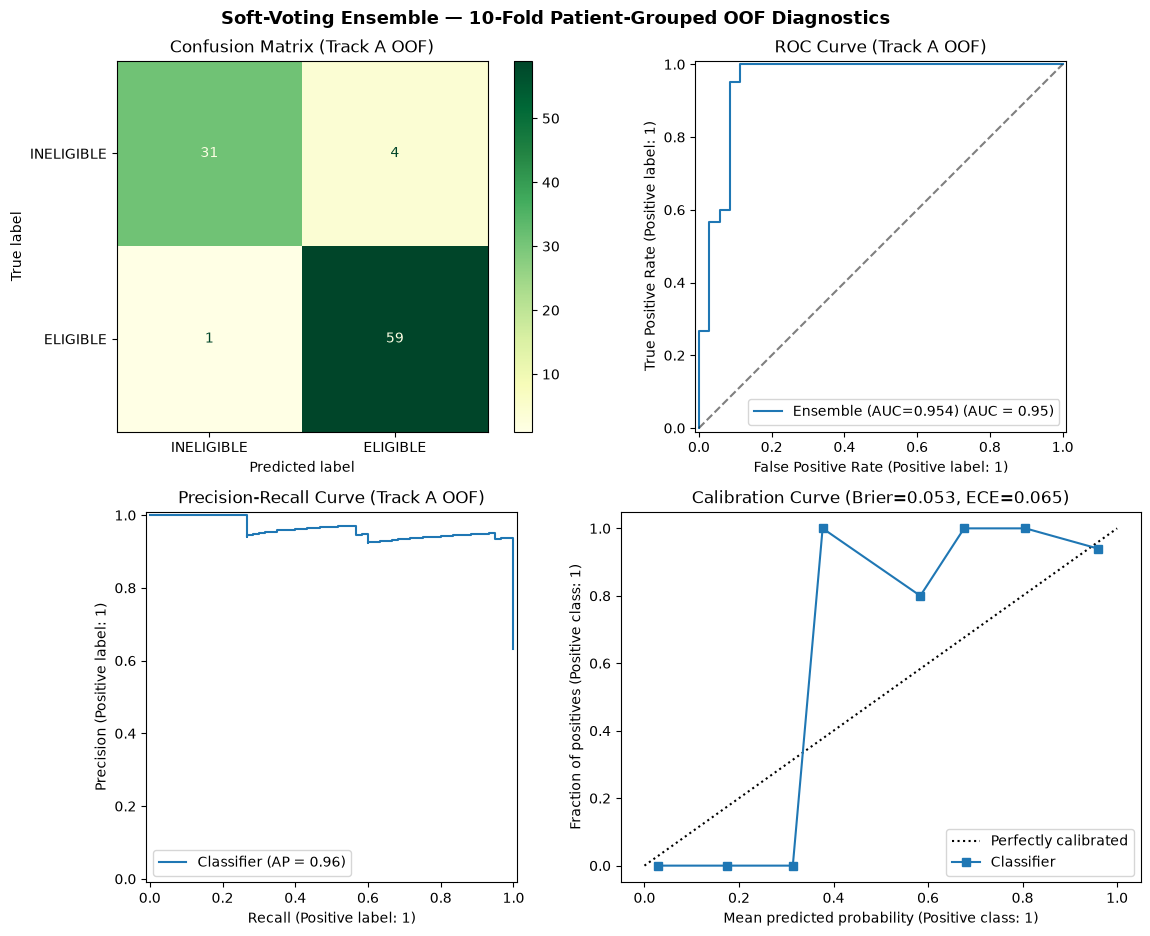

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
ConfusionMatrixDisplay.from_predictions(y_dev, (p_ens_a >= 0.5).astype(int), display_labels=["INELIGIBLE", "ELIGIBLE"], ax=axes[0, 0], cmap="YlGn")
axes[0, 0].set_title("Confusion Matrix (Track A OOF)")

RocCurveDisplay.from_predictions(y_dev, p_ens_a, ax=axes[0, 1], name=f"Ensemble (AUC={overall_a['roc_auc']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 1].set_title("ROC Curve (Track A OOF)")

PrecisionRecallDisplay.from_predictions(y_dev, p_ens_a, ax=axes[1, 0])
axes[1, 0].set_title("Precision-Recall Curve (Track A OOF)")

CalibrationDisplay.from_predictions(y_dev, p_ens_a, n_bins=8, ax=axes[1, 1])
axes[1, 1].set_title(f"Calibration Curve (Brier={overall_a['brier_score']:.3f}, ECE={overall_a['ece']:.3f})")

fig.suptitle("Soft-Voting Ensemble — 10-Fold Patient-Grouped OOF Diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "05_ensemble_oof_diagnostics.png", dpi=200)
plt.savefig(VIZ_DIR / "confusion_matrix_and_roc.png", dpi=200)
plt.show()

## 5. 10-Fold CV Stability & Base Model Probability Correlation

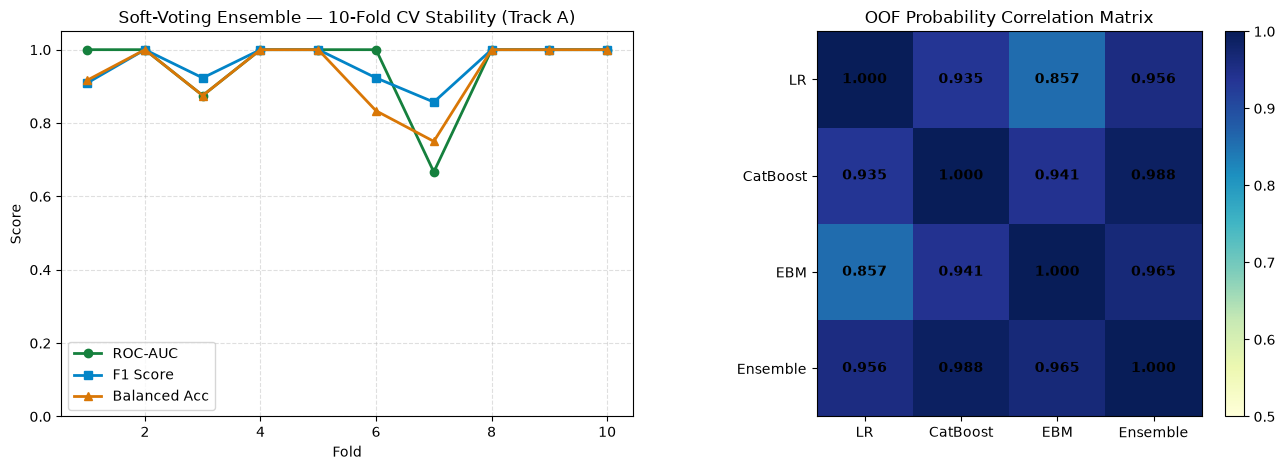

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(folds_a["fold"], folds_a["roc_auc"], marker="o", label="ROC-AUC", linewidth=2, color="#15803d")
axes[0].plot(folds_a["fold"], folds_a["f1"], marker="s", label="F1 Score", linewidth=2, color="#0284c7")
axes[0].plot(folds_a["fold"], folds_a["balanced_accuracy"], marker="^", label="Balanced Acc", linewidth=2, color="#d97706")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Soft-Voting Ensemble — 10-Fold CV Stability (Track A)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

corr_df = pd.DataFrame({"LR": p_lr_a, "CatBoost": p_cb_a, "EBM": p_ebm_a, "Ensemble": p_ens_a}).corr()
im = axes[1].imshow(corr_df.values, cmap="YlGnBu", vmin=0.5, vmax=1.0)
axes[1].set_xticks(range(len(corr_df.columns)))
axes[1].set_yticks(range(len(corr_df.columns)))
axes[1].set_xticklabels(corr_df.columns)
axes[1].set_yticklabels(corr_df.columns)
for i in range(len(corr_df)):
    for j in range(len(corr_df)):
        axes[1].text(j, i, f"{corr_df.values[i, j]:.3f}", ha="center", va="center", color="black", fontweight="bold")
axes[1].set_title("OOF Probability Correlation Matrix")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(VIZ_DIR / "cv_stability_and_correlation.png", dpi=200)
plt.show()